# Computation of Exposure Map using sat's FoV

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import ROOT, glob

plt.rcParams['figure.dpi'] = 400
plt.rcParams['savefig.dpi'] = 400

In [2]:
dirDir= "/home/users/l/lebrun/"
resultPath = dirDir + "results/"
dataPath = "/dpnc/beegfs/dampe/prod/FM/skim/6.0.0/v2/2016/01/"
filenames = [dataPath + "01_data_photon.root"]

In [3]:
for filename in filenames:
    # Get all files matching the pattern
    # Use glob to find all files that match the pattern
    files = sorted(glob.glob(filename))
print(files)


['/dpnc/beegfs/dampe/prod/FM/skim/6.0.0/v2/2016/01/01_data_photon.root']


In [4]:
treename='HousekeepingData/SatStatus'

rdf = ROOT.RDataFrame(treename, files)


Warning in <TClass::Init>: no dictionary for class DmpEvtBgoRaw is available
Warning in <TClass::Init>: no dictionary for class DmpEvtPsdHits is available
Warning in <TClass::Init>: no dictionary for class DmpEvtBgoHits is available
Warning in <TClass::Init>: no dictionary for class DmpEvtHeader is available
Warning in <TClass::Init>: no dictionary for class DmpFeeNavig is available
Warning in <TClass::Init>: no dictionary for class DmpStkSiCluster is available
Warning in <TClass::Init>: no dictionary for class DmpStkLadderAdc is available
Warning in <TClass::Init>: no dictionary for class DmpStkEventMetadata is available
Warning in <TClass::Init>: no dictionary for class DmpStkTrack is available
Warning in <TClass::Init>: no dictionary for class DmpStkTrackParams is available
Warning in <TClass::Init>: no dictionary for class DmpEvtNudRaw is available
Warning in <TClass::Init>: no dictionary for class DmpEvtPsdRec is available
Warning in <TClass::Init>: no dictionary for class DmpEvtB

In [5]:
print("Created RDataFrame")
df = rdf.AsNumpy(['DmpHKDSatStatus.fSecond', 'DmpHKDSatStatus.fMicrosecond',
                   'DmpHKDSatStatus.fPosition.fX', 
                   'DmpHKDSatStatus.fPosition.fY', 
                   'DmpHKDSatStatus.fPosition.fZ'])
print("Converted to numpy")
df = pd.DataFrame(df)
df.rename(columns={'DmpHKDSatStatus.fSecond': 'second', 
                   'DmpHKDSatStatus.fMicrosecond': 'microsecond',
                   'DmpHKDSatStatus.fPosition.fX': 'x',
                   'DmpHKDSatStatus.fPosition.fY': 'y',
                   'DmpHKDSatStatus.fPosition.fZ': 'z'}, inplace=True)
print("Converted to pandas")

Created RDataFrame
Converted to numpy
Converted to pandas


In [6]:
print(df.head())

     second  microsecond          x           y           z
0  94635645       500000 -5412551.0 -2250438.50  3585435.00
1  94635646       500000 -5416615.5 -2250894.50  3579008.25
2  94635647       500000 -5420674.0 -2251346.00  3572575.50
3  94635648       500000 -5424724.5 -2251795.75  3566139.50
4  94635649       500000 -5428770.0 -2252243.25  3559699.25


## Analyze date range

In [7]:
from astropy.time import Time, TimeDelta
import numpy as np


def met_to_time(seconds, microseconds):
    # Ensure input is numpy array
    seconds = np.asarray(seconds)
    microseconds = np.asarray(microseconds)

    # TimeDelta with precision preserved
    delta_sec = TimeDelta(seconds, format='sec')
    delta_ms = TimeDelta(microseconds * 1e-6, format='sec')  # ms to sec

    # MET epoch (2013-01-01T00:00:00 UTC)
    epoch = Time("2013-01-01T00:00:00", scale="utc")

    # Full time in UTC
    full_time = epoch + delta_sec + delta_ms

    # Return human-readable UTC string
    return full_time

def met_to_utc(seconds, microseconds):
    # Ensure input is numpy array
    seconds = np.asarray(seconds)
    microseconds = np.asarray(microseconds)

    # TimeDelta with precision preserved
    delta_sec = TimeDelta(seconds, format='sec')
    delta_ms = TimeDelta(microseconds * 1e-6, format='sec')  # ms to sec

    # MET epoch (2013-01-01T00:00:00 UTC)
    epoch = Time("2013-01-01T00:00:00", scale="utc")

    # Full time in UTC
    full_time = epoch + delta_sec + delta_ms

    # Return human-readable UTC string
    return full_time.utc

def met_to_utc_string(seconds, microseconds):
    # Ensure input is numpy array
    seconds = np.asarray(seconds)
    microseconds = np.asarray(microseconds)

    # TimeDelta with precision preserved
    delta_sec = TimeDelta(seconds, format='sec')
    delta_ms = TimeDelta(microseconds * 1e-6, format='sec')  # ms to sec

    # MET epoch (2013-01-01T00:00:00 UTC)
    epoch = Time("2013-01-01T00:00:00", scale="utc")

    # Full time in UTC
    full_time = epoch + delta_sec + delta_ms

    # Return human-readable UTC string
    return full_time.utc.iso


### Eliminate duplicates, sort

In [8]:
df = df.sort_values(by=['second', 'microsecond'])
# Print the number of entries
print("Number of entries:", len(df['second']))
df = df.drop_duplicates('second', keep='first')
# Print the number of entries with Delta_t != NaN
print("Number of entries w/o duplicates:", len(df['second']))
print(f"Timestamps span from {met_to_utc_string(df.iloc[0]['second'], df.iloc[0]['microsecond'])} to {met_to_utc_string(df.iloc[-1]['second'], df.iloc[-1]['microsecond'])}")

Number of entries: 91004
Number of entries w/o duplicates: 87019
Timestamps span from 2016-01-01 00:05:20.500 to 2016-01-02 00:16:35.500


## TEst : plot Z against time

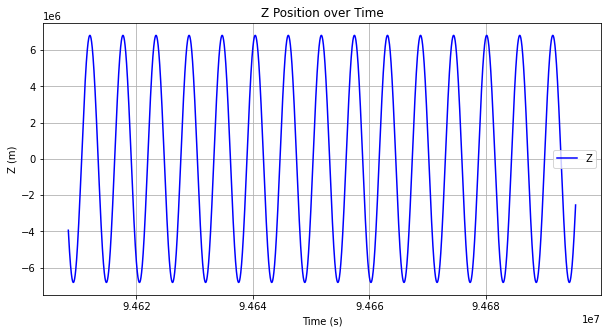

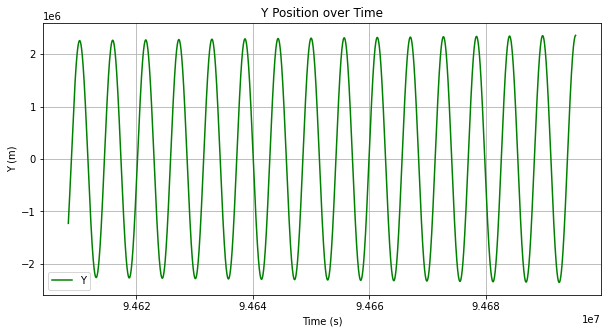

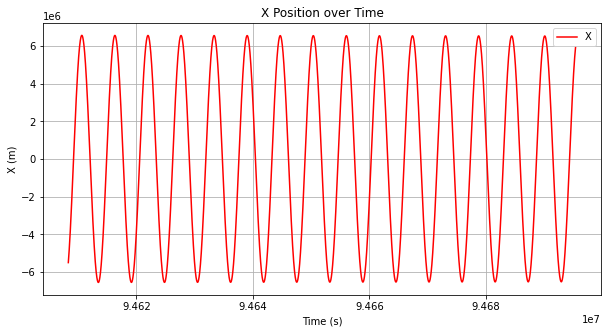

In [9]:
# Plot Z against time
plt.figure(figsize=(10, 5))
plt.plot(df['second'], df['z'], label='Z', color='blue')
plt.xlabel('Time (s)')
plt.ylabel('Z (m)') 
plt.title('Z Position over Time')
plt.grid()
plt.legend()
plt.show()

# Plot Y against time
plt.figure(figsize=(10, 5)) 
plt.plot(df['second'], df['y'], label='Y', color='green')
plt.xlabel('Time (s)')
plt.ylabel('Y (m)')
plt.title('Y Position over Time')
plt.grid()
plt.legend()
plt.show()
# Plot X against time
plt.figure(figsize=(10, 5))
plt.plot(df['second'], df['x'], label='X', color='red')
plt.xlabel('Time (s)')
plt.ylabel('X (m)')
plt.title('X Position over Time')
plt.grid()
plt.legend()
plt.show()

## Remove SAA and Glitches (TODO)

## Show satellite positions in Earth projection 

In [14]:
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from astropy.coordinates import GCRS, ITRS, EarthLocation, SkyCoord, CartesianRepresentation
from astropy.time import Time
from astropy import units as u
from astropy.coordinates import EarthLocation

location = EarthLocation.from_geocentric(0 *u.m , 0 * u.m , 0*u.m  )

# Your existing code up to this point...
# df now contains columns: 'second', 'microsecond', 'x', 'y', 'z', 'Delta_t'

def convert_icrs_to_earth_coordinates(x, y, z, time_seconds, time_microseconds, 
                                    time_reference='unix'):
    """
    Convert ICRS coordinates to Earth-fixed (ITRS) coordinates and then to lat/lon.
    
    Parameters:
    - x, y, z: Cartesian coordinates in ICRS frame (meters)
    - time_seconds, time_microseconds: Time arrays
    - time_reference: 'unix', 'gps', 'tai', 'utc', or 'custom'
    - epoch_offset: Offset in seconds if using custom time reference
    """
    
    # Convert time to astropy Time object
    total_time_seconds = time_seconds + time_microseconds * 1e-6
    
    if time_reference == 'unix':
        # Unix timestamp (seconds since 1970-01-01)
        astropy_time = Time(total_time_seconds, format='unix', scale='utc')
    elif time_reference == 'gps':
        # GPS time (seconds since 1980-01-06)
        astropy_time = Time(total_time_seconds, format='gps')
    elif time_reference == 'tai':
        # TAI time
        astropy_time = Time(total_time_seconds, format='tai')
    elif time_reference == 'utc':
        # UTC time
        astropy_time = Time(total_time_seconds, format='utc', scale='utc')
    elif time_reference == 'met':
        # MET time
        astropy_time = met_to_time(time_seconds, time_microseconds)
        print(astropy_time)
        print(type(astropy_time))
    else:
        print(f"Warning: Unknown time reference '{time_reference}', assuming UTC")
        astropy_time = Time(total_time_seconds, format='utc', scale='utc')
        

     # Build GCRS coordinate frame at each time
    positions = CartesianRepresentation(
        x=x * u.m,
        y=y * u.m,
        z=z * u.m
    )

    gcrs_coords = GCRS(positions, obstime=astropy_time)
    
    # Convert to Earth-fixed frame (ITRS), then to geographic coordinates
    itrs_coords = gcrs_coords.transform_to(ITRS(obstime=astropy_time))
    # Use ITRS and convert to EarthLocation
    earth_locs = EarthLocation(itrs_coords.x, itrs_coords.y, itrs_coords.z)

    print(earth_locs)

    geodetic = earth_locs.to_geodetic()

    latitudes = geodetic.lat.to(u.deg).value
    longitudes = geodetic.lon.to(u.deg).value
    heights = geodetic.height.to(u.km).value
    return latitudes, longitudes, heights, astropy_time

def analyze_orbital_characteristics(df, astropy_time):
    """Analyze the orbital characteristics of the satellite"""
    
    # Calculate orbital radius
    r = np.sqrt(df['x']**2 + df['y']**2 + df['z']**2)
    mean_radius_km = r.mean() / 1000
    mean_altitude_km = mean_radius_km - 6371.0
    
    print(f"\nOrbital Analysis:")
    print(f"Mean orbital radius: {mean_radius_km:.1f} km")
    print(f"Mean altitude: {mean_altitude_km:.1f} km")
    
    # Estimate orbital period
    total_duration = (astropy_time[-1] - astropy_time[0]).to(u.second).value
    
    # Theoretical orbital period using Kepler's third law
    G = 6.67430e-11  # m³/kg/s²
    M_earth = 5.972e24  # kg
    theoretical_period_s = 2 * np.pi * np.sqrt((mean_radius_km * 1000)**3 / (G * M_earth))
    theoretical_period_min = theoretical_period_s / 60
    
    print(f"Theoretical orbital period: {theoretical_period_min:.1f} minutes")
    print(f"Data duration: {total_duration/60:.1f} minutes ({total_duration/theoretical_period_s:.2f} orbits)")
    
    return mean_altitude_km, theoretical_period_min

# Main conversion process
print("Starting coordinate transformation from ICRS to Earth coordinates...")

# You may need to adjust the time_reference parameter based on your data:
# Options: 'unix', 'gps', 'tai', 'utc', 'met'
TIME_REFERENCE = 'met'  # Modify this based on your timestamp format

try:
    # Convert coordinates
    latitudes, longitudes, heights, astropy_time = convert_icrs_to_earth_coordinates(
        df['x'].values, df['y'].values, df['z'].values,
        df['second'].values, df['microsecond'].values,
        time_reference=TIME_REFERENCE
    )
    
    # Add results to dataframe
    df['lat'] = latitudes
    df['lon'] = longitudes
    df['altitude_km'] = heights
    df['astropy_time'] = astropy_time
    
    print(f"\nCoordinate conversion successful!")
    print(f"Latitude range: {df['lat'].min():.2f}° to {df['lat'].max():.2f}°")
    print(f"Longitude range: {df['lon'].min():.2f}° to {df['lon'].max():.2f}°")
    print(f"Altitude range: {df['altitude_km'].min():.1f} to {df['altitude_km'].max():.1f} km")
    
    # Analyze orbital characteristics
    mean_altitude, orbital_period = analyze_orbital_characteristics(df, astropy_time)
    
except Exception as e:
    print(f"Error in coordinate transformation: {e}")
    print("You may need to adjust the time_reference parameter or check your coordinate system.")
    print("Available options: 'unix', 'gps', 'tai', 'utc', 'met'")
    raise


Starting coordinate transformation from ICRS to Earth coordinates...
['2016-01-01T00:05:20.500' '2016-01-01T00:05:21.500'
 '2016-01-01T00:05:22.500' ... '2016-01-02T00:16:33.500'
 '2016-01-02T00:16:34.500' '2016-01-02T00:16:35.500']
<class 'astropy.time.core.Time'>
[(-134894.72049622,  5623705.59121688, -3947669.49520267)
 (-133199.29188581,  5619418.2745022 , -3953827.95808333)
 (-131504.99591543,  5615126.2630664 , -3959980.16400923) ...
 ( 740277.72493766, -6350564.48051687, -2549116.20204748)
 ( 739105.48111615, -6353511.14223016, -2542115.82674483)
 ( 737931.24733636, -6356449.99631223, -2535113.96212789)] m
Error in coordinate transformation: Invalid data-type for array
You may need to adjust the time_reference parameter or check your coordinate system.
Available options: 'unix', 'gps', 'tai', 'utc', 'met'


ValueError: Invalid data-type for array

In [ ]:

# Create the map plot
fig = plt.figure(figsize=(15, 10))
ax = plt.axes(projection=ccrs.PlateCarree())

# Add map features
ax.add_feature(cfeature.COASTLINE, linewidth=0.5)
ax.add_feature(cfeature.BORDERS, linewidth=0.5)
ax.add_feature(cfeature.OCEAN, color='lightblue', alpha=0.5)
ax.add_feature(cfeature.LAND, color='lightgray', alpha=0.5)

# Add gridlines
gl = ax.gridlines(draw_labels=True, dms=True, x_inline=False, y_inline=False)
gl.top_labels = False
gl.right_labels = False

# Plot satellite track colored by time
scatter = ax.scatter(df['lon'], df['lat'], 
                    c=df.index, 
                    s=3, 
                    cmap='viridis', 
                    alpha=0.8,
                    transform=ccrs.PlateCarree())

# Add colorbar
cbar = plt.colorbar(scatter, ax=ax, shrink=0.7, pad=0.02)
cbar.set_label('Time Index', rotation=270, labelpad=15)

# Plot the track as a line
ax.plot(df['lon'], df['lat'], 
        color='red', 
        linewidth=0.8, 
        alpha=0.7,
        transform=ccrs.PlateCarree())

# Mark start and end points
ax.plot(df['lon'].iloc[0], df['lat'].iloc[0], 
        'go', markersize=10, label='Start', transform=ccrs.PlateCarree())
ax.plot(df['lon'].iloc[-1], df['lat'].iloc[-1], 
        'ro', markersize=10, label='End', transform=ccrs.PlateCarree())

plt.title(f'Satellite Ground Track\nAltitude: {mean_altitude:.0f} km, Period: {orbital_period:.1f} min', 
          fontsize=16, pad=20)
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()

# Create focused map if needed
def plot_focused_satellite_track(df, margin=10):
    """Create a focused view of the satellite track"""
    
    fig = plt.figure(figsize=(12, 8))
    
    # Calculate bounds
    lon_min, lon_max = df['lon'].min() - margin, df['lon'].max() + margin
    lat_min, lat_max = df['lat'].min() - margin, df['lat'].max() + margin
    
    ax = plt.axes(projection=ccrs.PlateCarree())
    ax.set_extent([lon_min, lon_max, lat_min, lat_max], crs=ccrs.PlateCarree())
    
    # Add features
    ax.add_feature(cfeature.COASTLINE, linewidth=1)
    ax.add_feature(cfeature.BORDERS, linewidth=0.8)
    ax.add_feature(cfeature.OCEAN, color='lightblue', alpha=0.6)
    ax.add_feature(cfeature.LAND, color='lightgray', alpha=0.8)
    ax.add_feature(cfeature.LAKES, color='lightblue', alpha=0.5)
    ax.add_feature(cfeature.RIVERS, linewidth=0.5)
    
    # Add gridlines
    gl = ax.gridlines(draw_labels=True, dms=True, x_inline=False, y_inline=False)
    gl.top_labels = False
    gl.right_labels = False
    
    # Plot track colored by altitude
    scatter = ax.scatter(df['lon'], df['lat'], 
                        c=df['altitude_km'], 
                        s=15, 
                        cmap='plasma', 
                        alpha=0.9,
                        transform=ccrs.PlateCarree())
    
    # Plot track line
    ax.plot(df['lon'], df['lat'], 
            color='darkred', 
            linewidth=1.5, 
            alpha=0.8,
            transform=ccrs.PlateCarree())
    
    cbar = plt.colorbar(scatter, ax=ax, shrink=0.7)
    cbar.set_label('Altitude (km)', rotation=270, labelpad=15)
    
    # Mark start/end
    ax.plot(df['lon'].iloc[0], df['lat'].iloc[0], 
            'go', markersize=12, label='Start', transform=ccrs.PlateCarree())
    ax.plot(df['lon'].iloc[-1], df['lat'].iloc[-1], 
            'ro', markersize=12, label='End', transform=ccrs.PlateCarree())
    
    plt.title('Satellite Ground Track (Focused View)', fontsize=14, pad=15)
    plt.legend()
    plt.tight_layout()
    plt.show()

# Create focused plot
plot_focused_satellite_track(df)

# Time series analysis
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# Convert time to hours for plotting
time_hours = (df.index * df['Delta_t'].iloc[0]) / 3600

# Latitude vs time
axes[0,0].plot(time_hours, df['lat'], 'b-', linewidth=1)
axes[0,0].set_ylabel('Latitude (°)')
axes[0,0].set_title('Latitude vs Time')
axes[0,0].grid(True, alpha=0.3)

# Longitude vs time
axes[0,1].plot(time_hours, df['lon'], 'r-', linewidth=1)
axes[0,1].set_ylabel('Longitude (°)')
axes[0,1].set_title('Longitude vs Time')
axes[0,1].grid(True, alpha=0.3)

# Altitude vs time
axes[1,0].plot(time_hours, df['altitude_km'], 'g-', linewidth=1)
axes[1,0].set_ylabel('Altitude (km)')
axes[1,0].set_xlabel('Time (hours)')
axes[1,0].set_title('Altitude vs Time')
axes[1,0].grid(True, alpha=0.3)

# Ground track in lat/lon space
axes[1,1].plot(df['lon'], df['lat'], 'purple', linewidth=1, alpha=0.7)
axes[1,1].scatter(df['lon'].iloc[0], df['lat'].iloc[0], c='green', s=50, label='Start')
axes[1,1].scatter(df['lon'].iloc[-1], df['lat'].iloc[-1], c='red', s=50, label='End')
axes[1,1].set_xlabel('Longitude (°)')
axes[1,1].set_ylabel('Latitude (°)')
axes[1,1].set_title('Ground Track')
axes[1,1].grid(True, alpha=0.3)
axes[1,1].legend()

plt.tight_layout()
plt.show()

print(f"\nSatellite tracking complete!")
print(f"Total data points: {len(df)}")
print(f"Time span: {time_hours[-1]:.2f} hours")
print(f"Ground track covers {df['lat'].max() - df['lat'].min():.1f}° latitude")
print(f"Ground track covers {df['lon'].max() - df['lon'].min():.1f}° longitude")